
# Rigorous Re-analysis of the Heart Failure Clinical Records Study

**Paper:** *A machine learning approach for risk factors analysis and survival prediction of Heart Failure patients*  
**Journal:** *Healthcare Analytics* (2023), 100182  
**Purpose:** reproduce the paper where possible, explicitly test its reported claims, and build a leakage-free analysis suitable for a reproducibility study.

---

## What this notebook changes

The paper reports a Random Forest accuracy of **97.78%**. This notebook does **not** assume that number is correct or incorrect in advance.

Instead, it separates three questions:

1. **What does the paper actually say?**
2. **Can the reported numbers be reproduced from the available 299-row dataset?**
3. **What performance do we obtain under a leakage-free evaluation protocol?**

The primary analysis therefore:

- keeps the original patient-level data;
- excludes `time` from the primary classification model because it is follow-up information rather than a baseline predictor;
- never applies SMOTE to validation/test data;
- uses **SMOTENC** for the mixed continuous/binary feature set;
- reports repeated stratified cross-validation with confidence intervals;
- compares against a majority-class baseline and logistic regression;
- reports probability-based log loss and ROC-AUC;
- performs permutation importance on held-out folds;
- performs Cox survival analysis on the **original, non-SMOTE survival data**;
- standardizes continuous covariates before comparing Cox coefficients;
- checks the proportional-hazards assumption;
- reports C-index for survival discrimination;
- treats Kaplan–Meier 40/60 splits as descriptive sensitivity analysis rather than causal "safe ranges";
- explicitly audits the internal contradictions identified in the paper.

> **Important:** statements about the paper that are not directly reproducible from the dataset are labelled as "not reproducible" or "inference", rather than being presented as proven errors.



## Notebook structure

1. Environment and reproducibility
2. Load and validate the dataset
3. Audit the paper's reported cohort
4. Exploratory analysis without outcome leakage
5. Reproduce the paper-style preprocessing as a **diagnostic**, not as the primary result
6. Paper-style 70/30 benchmark
7. Leakage-free 70/30 benchmark
8. Repeated stratified cross-validation
9. SMOTENC vs class weights vs no balancing
10. Calibration and threshold analysis
11. Held-out permutation feature importance
12. Optional SHAP analysis
13. Survival analysis: Cox PH
14. Proportional-hazards diagnostics
15. Kaplan–Meier and log-rank sensitivity analysis
16. Optional Random Survival Forest
17. Direct audit of the paper's claims
18. Reproducibility summary
19. Export tables/results


In [1]:

# =============================================================================
# 1. ENVIRONMENT
# =============================================================================
# If an import fails in a fresh environment, uncomment the pip line below.
# %pip install -q numpy pandas scipy matplotlib seaborn scikit-learn imbalanced-learn \
#     xgboost lifelines statsmodels openpyxl

import os
import sys
import warnings
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve, CalibrationDisplay
from sklearn.utils import resample

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from lifelines.utils import concordance_index

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 5)

print("Python:", sys.version)
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Python: 3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]
Platform: Windows-11-10.0.26300-SP0
NumPy: 2.5.1
Pandas: 2.3.3



## 2. Load the dataset

Set `DATA_PATH` to the CSV used in the original implementation.

The expected dataset has:

- 299 observations;
- 12 clinical columns plus `DEATH_EVENT`;
- `time` = follow-up duration;
- `DEATH_EVENT` = observed death during follow-up.

If your CSV is not in the notebook directory, change `DATA_PATH`.


In [2]:

# =============================================================================
# 2. DATA INGESTION
# =============================================================================
candidates = [Path("heart_failure_clinical_records_dataset.csv"), Path("../data/heart_failure_clinical_records_dataset.csv"), Path("../../data/heart_failure_clinical_records_dataset.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), Path("heart_failure_clinical_records_dataset.csv"))

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}.\n"
        "Put heart_failure_clinical_records_dataset.csv next to this notebook "
        "or change DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape}")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))

print("\nDuplicate rows:", df.duplicated().sum())

if "DEATH_EVENT" in df.columns:
    print("\nTarget distribution:")
    target_table = (
        df["DEATH_EVENT"]
        .value_counts()
        .sort_index()
        .rename(index={0: "Survived / censored", 1: "Death observed"})
        .to_frame("count")
    )
    target_table["percent"] = 100 * target_table["count"] / len(df)
    display(target_table.round(2))


Shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



Column names:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']

Missing values:


,missing
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0



Duplicate rows: 0

Target distribution:


,count,percent
DEATH_EVENT,,
Survived / censored,203,67.89
Death observed,96,32.11


In [3]:

# =============================================================================
# 2A. DATA QUALITY / DOMAIN CHECKS
# =============================================================================
expected_columns = [
    "age", "anaemia", "creatinine_phosphokinase", "diabetes",
    "ejection_fraction", "high_blood_pressure", "platelets",
    "serum_creatinine", "serum_sodium", "sex", "smoking",
    "time", "DEATH_EVENT"
]

missing_expected = [c for c in expected_columns if c not in df.columns]
extra_columns = [c for c in df.columns if c not in expected_columns]

print("Missing expected columns:", missing_expected)
print("Extra columns:", extra_columns)

binary_cols = [
    "anaemia", "diabetes", "high_blood_pressure",
    "sex", "smoking", "DEATH_EVENT"
]

for c in binary_cols:
    if c in df.columns:
        vals = sorted(df[c].dropna().unique().tolist())
        print(f"{c:25s}: {vals}")

print("\nSimple column sums:")
display(df.sum(numeric_only=True).to_frame("sum"))

print("\nDescriptive statistics:")
display(df.describe().T.round(3))


Missing expected columns: []
Extra columns: []
anaemia                  : [0, 1]
diabetes                 : [0, 1]
high_blood_pressure      : [0, 1]
sex                      : [0, 1]
smoking                  : [0, 1]
DEATH_EVENT              : [0, 1]

Simple column sums:


,sum
age,1.818933e+04
anaemia,1.290000e+02
creatinine_phosphokinase,1.739700e+05
diabetes,1.250000e+02
ejection_fraction,1.138700e+04
high_blood_pressure,1.050000e+02
platelets,7.874405e+07
serum_creatinine,4.167700e+02
serum_sodium,4.085100e+04
sex,1.940000e+02



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.834,11.895,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431,0.496,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839,970.288,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418,0.494,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.084,11.835,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351,0.478,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029,97804.237,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.394,1.035,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625,4.412,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.649,0.478,0.0,0.0,1.0,1.0,1.0



## 3. Audit the paper's cohort description

The paper states that the dataset contains 299 patients, with 96 observed deaths and 203 survivors. It also reports several categorical counts and p-values.

The notebook computes the corresponding quantities **from the loaded CSV**. It does not overwrite the dataset to make it agree with the paper.

This is important because a different 299-row dataset can produce the same sample size but different feature distributions and therefore different model results.


In [4]:

# =============================================================================
# 3. COHORT AUDIT
# =============================================================================
print("N =", len(df))
print("Deaths =", int(df["DEATH_EVENT"].sum()))
print("Non-deaths =", int((df["DEATH_EVENT"] == 0).sum()))

paper_claims = pd.DataFrame({
    "Quantity": [
        "Total N", "Deaths", "Non-deaths",
        "Male (sex=1)", "Diabetes (1)", "High BP (1)",
        "Smoking (1)", "Anaemia (1)"
    ],
    "Paper reported": [299, 96, 203, 179, 167, 133, 89, 113],
    "Dataset value": [
        len(df),
        int(df["DEATH_EVENT"].sum()),
        int((df["DEATH_EVENT"] == 0).sum()),
        int((df["sex"] == 1).sum()),
        int((df["diabetes"] == 1).sum()),
        int((df["high_blood_pressure"] == 1).sum()),
        int((df["smoking"] == 1).sum()),
        int((df["anaemia"] == 1).sum()),
    ]
})
paper_claims["Difference"] = paper_claims["Dataset value"] - paper_claims["Paper reported"]
display(paper_claims)

print("\nInterpretation:")
print(
    "If the dataset values differ from the paper while N remains 299, "
    "the paper's reported cohort is not directly reproducible from this CSV."
)


N = 299
Deaths = 96
Non-deaths = 203


,Quantity,Paper reported,Dataset value,Difference
0,Total N,299,299,0
1,Deaths,96,96,0
2,Non-deaths,203,203,0
3,Male (sex=1),179,194,15
4,Diabetes (1),167,125,-42
5,High BP (1),133,105,-28
6,Smoking (1),89,96,7
7,Anaemia (1),113,129,16



Interpretation:
If the dataset values differ from the paper while N remains 299, the paper's reported cohort is not directly reproducible from this CSV.


In [5]:

# =============================================================================
# 3A. TABLE-2 STYLE GROUP COMPARISONS
# =============================================================================
categorical = [
    "sex", "smoking", "anaemia", "diabetes", "high_blood_pressure"
]
numeric = [
    "age", "creatinine_phosphokinase", "ejection_fraction",
    "platelets", "serum_creatinine", "serum_sodium", "time"
]

dead = df.loc[df["DEATH_EVENT"] == 1]
survived = df.loc[df["DEATH_EVENT"] == 0]

cat_rows = []
for col in categorical:
    table = pd.crosstab(df[col], df["DEATH_EVENT"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    for value in sorted(df[col].dropna().unique()):
        cat_rows.append({
            "feature": col,
            "value": value,
            "n": int((df[col] == value).sum()),
            "death_n": int((dead[col] == value).sum()),
            "survived_n": int((survived[col] == value).sum()),
            "chi_square_p": p
        })

cat_audit = pd.DataFrame(cat_rows)
display(cat_audit.round(4))

num_rows = []
for col in numeric:
    # Welch t-test; add Mann-Whitney as a non-parametric sensitivity check.
    t, p_t = stats.ttest_ind(dead[col], survived[col], equal_var=False)
    u, p_u = stats.mannwhitneyu(dead[col], survived[col], alternative="two-sided")
    num_rows.append({
        "feature": col,
        "dead_mean": dead[col].mean(),
        "survived_mean": survived[col].mean(),
        "dead_median": dead[col].median(),
        "survived_median": survived[col].median(),
        "Welch_t_p": p_t,
        "Mann_Whitney_p": p_u
    })

num_audit = pd.DataFrame(num_rows)
display(num_audit.round(5))


,feature,value,n,death_n,survived_n,chi_square_p
0,sex,0,105,34,71,1.0000
1,sex,1,194,62,132,1.0000
2,smoking,0,203,66,137,0.9318
3,smoking,1,96,30,66,0.9318
4,anaemia,0,170,50,120,0.3073
5,anaemia,1,129,46,83,0.3073
6,diabetes,0,174,56,118,1.0000
7,diabetes,1,125,40,85,1.0000
8,high_blood_pressure,0,194,57,137,0.2141
9,high_blood_pressure,1,105,39,66,0.2141


,feature,dead_mean,survived_mean,dead_median,survived_median,Welch_t_p,Mann_Whitney_p
0,age,65.21528,58.76191,65.0,60.0,0.00005,0.00017
1,creatinine_phosphokinase,670.19792,540.05419,259.0,245.0,0.36922,0.68404
2,ejection_fraction,33.46875,40.26601,30.0,38.0,0.00001,0.00000
3,platelets,256381.04479,266657.48990,258500.0,263000.0,0.39932,0.42556
4,serum_creatinine,1.83583,1.18488,1.3,1.0,0.00006,0.00000
5,serum_sodium,135.37500,137.21675,135.5,137.0,0.00187,0.00029
6,time,70.88542,158.33990,44.5,172.0,0.00000,0.00000



### Why the p-values are not treated as "risk factors"

A p-value answers a hypothesis-testing question. It is not an effect size and it is not a causal risk-factor score.

For the primary risk-factor analysis later in this notebook we therefore use:

- held-out permutation importance for predictive contribution;
- standardized Cox hazard ratios for survival associations;
- confidence intervals and p-values as inferential diagnostics;
- no language such as "safe range" from a KDE alone.


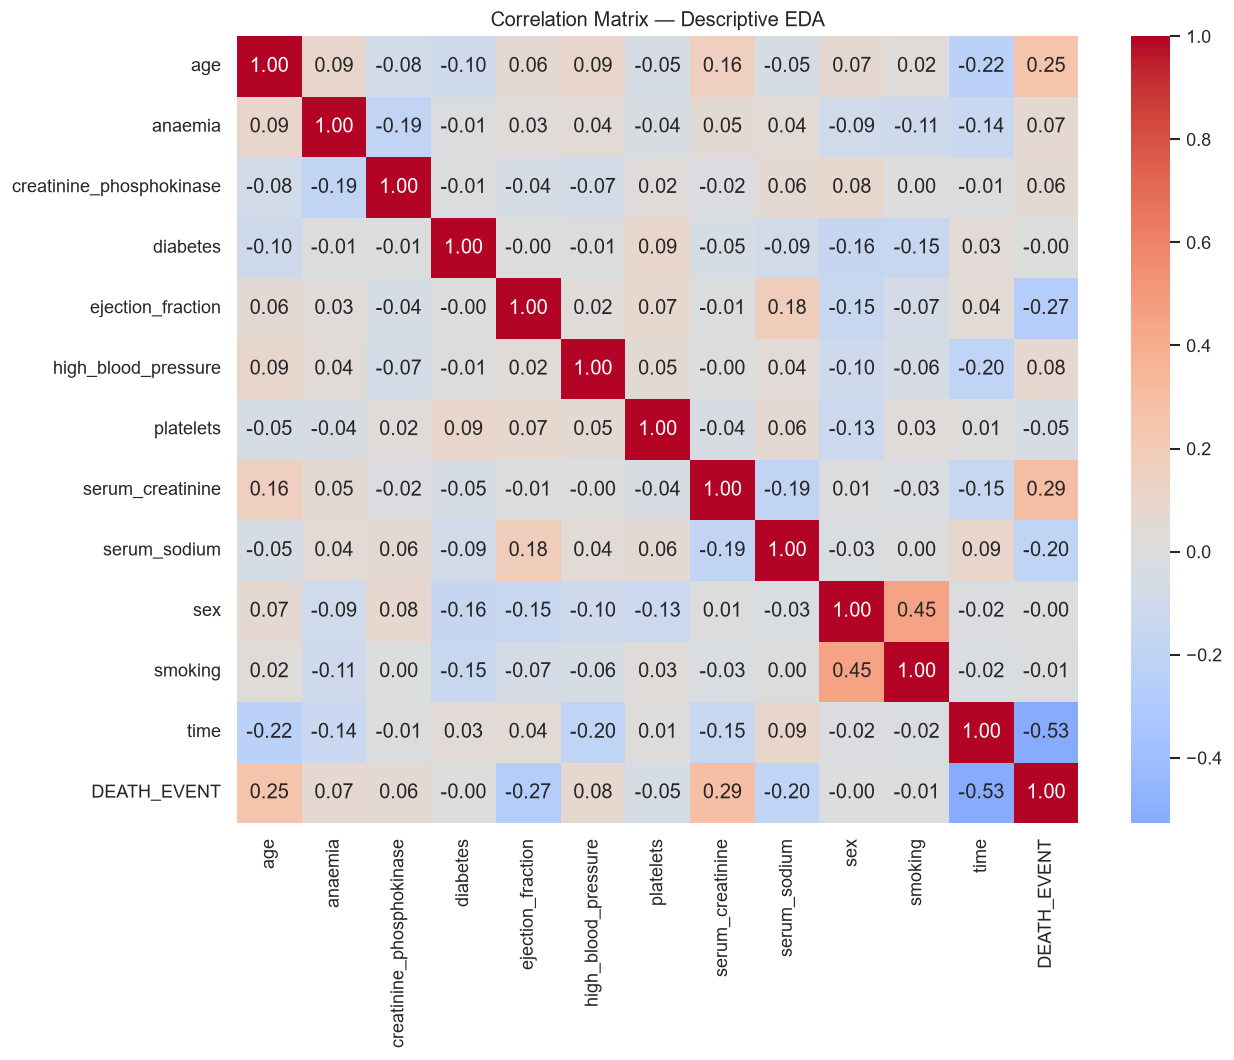

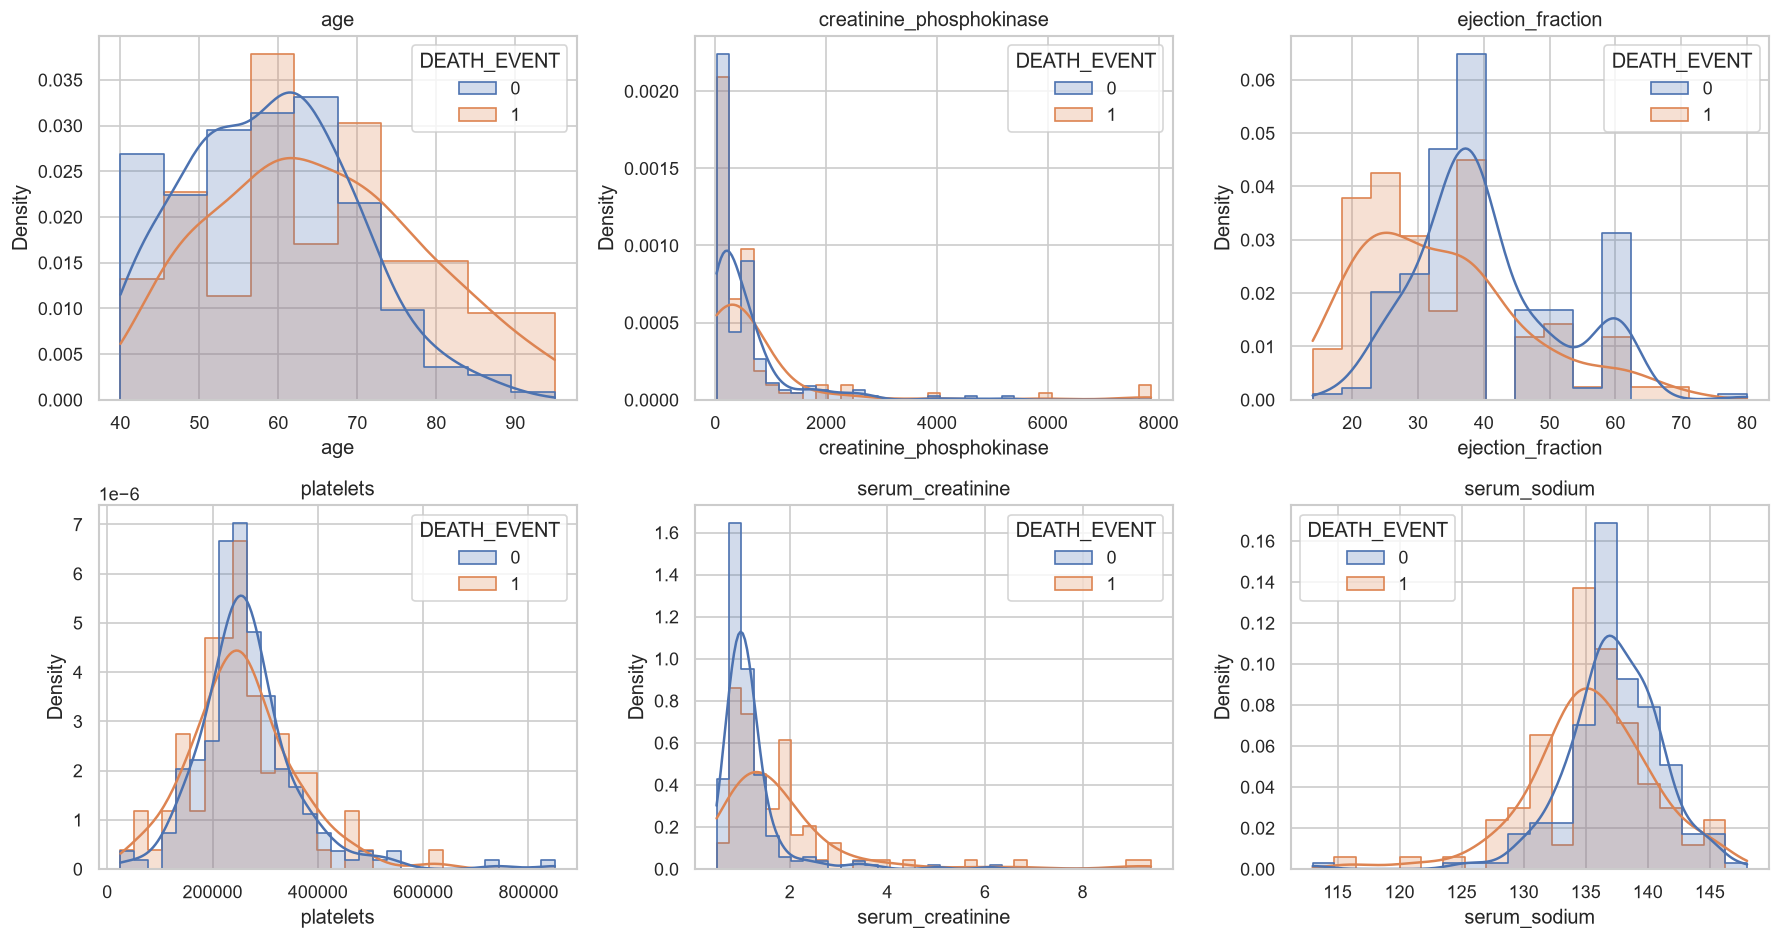

In [6]:

# =============================================================================
# 4. EXPLORATORY DATA ANALYSIS
# =============================================================================
# Correlation matrix is descriptive only. It is NOT used for model validation.
plt.figure(figsize=(11, 9))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Matrix — Descriptive EDA")
plt.tight_layout()
plt.show()

# Distribution plots: use raw data so we can see the actual cohort.
eda_features = [
    "age", "creatinine_phosphokinase", "ejection_fraction",
    "platelets", "serum_creatinine", "serum_sodium"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), eda_features):
    sns.histplot(
        data=df, x=col, hue="DEATH_EVENT",
        kde=True, stat="density", common_norm=False,
        element="step", ax=ax
    )
    ax.set_title(col)
plt.tight_layout()
plt.show()



## 5. Paper-style preprocessing: diagnostic only

The paper describes outlier removal and SMOTE before model fitting. The exact implementation is not sufficiently specified to reconstruct it uniquely.

We therefore run a **diagnostic reproduction**:

- sequential 1.5×IQR filtering on the seven continuous variables used in the paper's boxplots;
- global SMOTE;
- 70/30 split.

This section is deliberately labelled **leakage-prone**. It must not be used as the primary clinical performance estimate.

For mixed continuous/binary features, ordinary SMOTE is also not ideal because interpolation can create fractional binary values. The corrected pipeline later uses **SMOTENC** inside the training folds only.


In [7]:

# =============================================================================
# 5. PAPER-STYLE DIAGNOSTIC PREPROCESSING
# =============================================================================
outlier_cols = [
    "age", "creatinine_phosphokinase", "ejection_fraction",
    "platelets", "serum_creatinine", "serum_sodium"
]

df_iqr = df.copy()
removal_log = []

for col in outlier_cols:
    before = len(df_iqr)
    q1 = df_iqr[col].quantile(0.25)
    q3 = df_iqr[col].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    mask = df_iqr[col].between(lo, hi)
    df_iqr = df_iqr.loc[mask].copy()

    removal_log.append({
        "feature": col,
        "lower": lo,
        "upper": hi,
        "before": before,
        "after": len(df_iqr),
        "removed_this_step": before - len(df_iqr)
    })

removal_log = pd.DataFrame(removal_log)
display(removal_log)

print(f"Original N: {len(df)}")
print(f"After sequential IQR filtering: {len(df_iqr)}")
print(f"Total removed: {len(df) - len(df_iqr)}")

# Global SMOTE only for the diagnostic reproduction.
clf_features = [c for c in df.columns if c not in ["DEATH_EVENT", "time"]]
X_iqr = df_iqr[clf_features]
y_iqr = df_iqr["DEATH_EVENT"]

binary_features = [
    c for c in clf_features
    if set(df[c].dropna().unique()).issubset({0, 1})
]
categorical_indices = [clf_features.index(c) for c in binary_features]

# Diagnostic: ordinary SMOTE, because this is closest to the paper's wording.
from imblearn.over_sampling import SMOTE

smote_global = SMOTE(random_state=RANDOM_STATE)
X_global_smote, y_global_smote = smote_global.fit_resample(X_iqr, y_iqr)

print("\nGlobal SMOTE result:")
print(pd.Series(y_global_smote).value_counts().sort_index())

X_ps_train, X_ps_test, y_ps_train, y_ps_test = train_test_split(
    X_global_smote,
    y_global_smote,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_global_smote
)

print("Paper-style diagnostic split:", X_ps_train.shape, X_ps_test.shape)


,feature,lower,upper,before,after,removed_this_step
0,age,22.50,98.50,299,299,0
1,creatinine_phosphokinase,-581.75,1280.25,299,270,29
2,ejection_fraction,7.50,67.50,270,268,2
3,platelets,73875.00,440875.00,268,250,18
4,serum_creatinine,0.15,2.15,250,227,23
5,serum_sodium,125.00,149.00,227,224,3


Original N: 299
After sequential IQR filtering: 224
Total removed: 75

Global SMOTE result:
DEATH_EVENT
0    163
1    163
Name: count, dtype: int64
Paper-style diagnostic split: (228, 11) (98, 11)



## 6. Paper-style model benchmark

The paper reports:

- DT: `criterion='gini'`, `max_depth=5`
- RF: `n_estimators=65`, `max_depth=8`
- XGB: `learning_rate=0.59`
- GB: `n_estimators=100`

The notebook uses those parameters for the diagnostic benchmark.

**DTR is not included in the primary classification comparison** because a `DecisionTreeRegressor` predicts a continuous target and its `.score()` is R², not classification accuracy. If one wants a classification tree, the correct model is `DecisionTreeClassifier`.


In [8]:

# =============================================================================
# 6. PAPER-STYLE DIAGNOSTIC MODELS
# =============================================================================
paper_models = {
    "DT": DecisionTreeClassifier(
        criterion="gini", max_depth=5, random_state=RANDOM_STATE
    ),
    "RF": RandomForestClassifier(
        n_estimators=65, max_depth=8, random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "XGB": XGBClassifier(
        learning_rate=0.59,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "GB": GradientBoostingClassifier(
        n_estimators=100, random_state=RANDOM_STATE
    ),
}

paper_rows = []

for name, model in paper_models.items():
    model.fit(X_ps_train, y_ps_train)
    pred = model.predict(X_ps_test)
    prob = model.predict_proba(X_ps_test)[:, 1]

    paper_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_ps_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_ps_test, pred),
        "Precision": precision_score(y_ps_test, pred, zero_division=0),
        "Recall": recall_score(y_ps_test, pred, zero_division=0),
        "F1": f1_score(y_ps_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_ps_test, prob),
        "PR-AUC": average_precision_score(y_ps_test, prob),
        "Log Loss": log_loss(y_ps_test, prob),
        "Brier": brier_score_loss(y_ps_test, prob),
    })

paper_style_results = pd.DataFrame(paper_rows).sort_values("Accuracy", ascending=False)
display(paper_style_results.round(4))

print("\nThis table is a diagnostic reproduction, NOT the primary performance claim.")


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier
1,RF,0.8571,0.8571,0.8571,0.8571,0.8571,0.9288,0.9256,0.3936,0.1212
2,XGB,0.8163,0.8163,0.7925,0.8571,0.8235,0.8759,0.8695,0.5281,0.1542
3,GB,0.8061,0.8061,0.7885,0.8367,0.8119,0.8780,0.8767,0.4377,0.1397
0,DT,0.7449,0.7449,0.7308,0.7755,0.7525,0.7697,0.7088,4.7452,0.2246



This table is a diagnostic reproduction, NOT the primary performance claim.



## 7. Leakage-free evaluation

### Primary principle

The test/validation observations must remain untouched.

For the primary analysis:

1. Split or cross-validate the original 299 patients.
2. Fit preprocessing using training data only.
3. Apply SMOTENC only to the training portion.
4. Evaluate on the untouched validation/test patients.

`time` is excluded from the primary classifier because it is follow-up information. It can be analysed separately in a sensitivity experiment, but including it as a baseline predictor changes the prediction question.


In [9]:

# =============================================================================
# 7. LEAKAGE-FREE 70/30 HOLDOUT
# =============================================================================
X = df[clf_features].copy()
y = df["DEATH_EVENT"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

binary_features = [
    c for c in clf_features
    if set(df[c].dropna().unique()).issubset({0, 1})
]
categorical_indices = [clf_features.index(c) for c in binary_features]

def make_smotenc_pipeline(model):
    return ImbPipeline([
        ("smotenc", SMOTENC(
            categorical_features=categorical_indices,
            random_state=RANDOM_STATE
        )),
        ("model", model)
    ])

corrected_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000, class_weight=None, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, criterion="gini", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=65, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        learning_rate=0.1, eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
}

holdout_rows = []

for name, model in corrected_models.items():
    pipe = make_smotenc_pipeline(model)
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    holdout_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
        "Log Loss": log_loss(y_test, prob),
        "Brier": brier_score_loss(y_test, prob),
    })

holdout_results = pd.DataFrame(holdout_rows).sort_values("ROC-AUC", ascending=False)
display(holdout_results.round(4))


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier
4,XGBoost,0.7000,0.6792,0.5294,0.6207,0.5714,0.7931,0.6893,0.6086,0.2002
2,Random Forest,0.7444,0.7120,0.6000,0.6207,0.6102,0.7846,0.6343,0.5399,0.1811
3,Gradient Boosting,0.7111,0.6783,0.5484,0.5862,0.5667,0.7750,0.6207,0.5841,0.1947
0,Logistic Regression,0.7111,0.6783,0.5484,0.5862,0.5667,0.7575,0.5662,0.6097,0.1920
1,Decision Tree,0.7222,0.6956,0.5625,0.6207,0.5902,0.7504,0.5529,1.8249,0.2258


In [10]:

# Confusion matrix and classification report for the strongest ROC-AUC model
best_name = holdout_results.iloc[0]["Model"]
best_model = make_smotenc_pipeline(corrected_models[best_name])
best_model.fit(X_train, y_train)

best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

print("Best holdout model by ROC-AUC:", best_name)
print("\nConfusion matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, best_pred),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

print("\nClassification report:")
print(classification_report(y_test, best_pred, digits=4, zero_division=0))


Best holdout model by ROC-AUC: XGBoost

Confusion matrix:


,Predicted 0,Predicted 1
Actual 0,45,16
Actual 1,11,18



Classification report:
              precision    recall  f1-score   support

           0     0.8036    0.7377    0.7692        61
           1     0.5294    0.6207    0.5714        29

    accuracy                         0.7000        90
   macro avg     0.6665    0.6792    0.6703        90
weighted avg     0.7152    0.7000    0.7055        90




## 8. Repeated stratified cross-validation

A single 70/30 split can change substantially when there are only 299 observations.

The primary classifier benchmark therefore uses **10-fold repeated stratified cross-validation**. SMOTENC is fitted independently inside each training fold.

We report:

- mean ± standard deviation across folds;
- pooled out-of-fold predictions;
- ROC-AUC;
- PR-AUC;
- accuracy;
- balanced accuracy;
- precision;
- recall;
- F1;
- probability-based log loss;
- Brier score.

This is the main performance estimate in the notebook.


In [11]:

# =============================================================================
# 8. REPEATED STRATIFIED CV
# =============================================================================
cv = RepeatedStratifiedKFold(
    n_splits=10,
    n_repeats=5,
    random_state=RANDOM_STATE
)

cv_rows = []
oof_store = {}

for name, model in corrected_models.items():
    fold_rows = []
    all_true, all_prob, all_pred = [], [], []

    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, y), start=1):
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]

        pipe = make_smotenc_pipeline(model)
        pipe.fit(X_tr, y_tr)

        pred = pipe.predict(X_va)
        prob = pipe.predict_proba(X_va)[:, 1]

        fold_rows.append({
            "fold": fold,
            "accuracy": accuracy_score(y_va, pred),
            "balanced_accuracy": balanced_accuracy_score(y_va, pred),
            "precision": precision_score(y_va, pred, zero_division=0),
            "recall": recall_score(y_va, pred, zero_division=0),
            "f1": f1_score(y_va, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_va, prob),
            "pr_auc": average_precision_score(y_va, prob),
            "log_loss": log_loss(y_va, prob),
            "brier": brier_score_loss(y_va, prob),
        })

        all_true.extend(y_va.tolist())
        all_prob.extend(prob.tolist())
        all_pred.extend(pred.tolist())

    fold_df = pd.DataFrame(fold_rows)
    oof_store[name] = {
        "y_true": np.array(all_true),
        "prob": np.array(all_prob),
        "pred": np.array(all_pred),
        "folds": fold_df
    }

    for metric in [
        "accuracy", "balanced_accuracy", "precision", "recall",
        "f1", "roc_auc", "pr_auc", "log_loss", "brier"
    ]:
        cv_rows.append({
            "Model": name,
            "Metric": metric,
            "Mean": fold_df[metric].mean(),
            "SD": fold_df[metric].std(ddof=1),
            "Lower_95": fold_df[metric].mean() - 1.96 * fold_df[metric].std(ddof=1) / np.sqrt(len(fold_df)),
            "Upper_95": fold_df[metric].mean() + 1.96 * fold_df[metric].std(ddof=1) / np.sqrt(len(fold_df)),
        })

cv_long = pd.DataFrame(cv_rows)
cv_summary = cv_long.pivot(index="Model", columns="Metric", values="Mean")
display(cv_summary.round(4))

print("\nRepeated-CV mean ± SD:")
for model_name in corrected_models:
    sub = cv_long[cv_long["Model"] == model_name]
    print("\n", model_name)
    for metric in ["accuracy", "balanced_accuracy", "f1", "roc_auc", "pr_auc", "log_loss", "brier"]:
        r = sub[sub["Metric"] == metric].iloc[0]
        print(f"  {metric:20s}: {r['Mean']:.3f} ± {r['SD']:.3f}")


Metric,accuracy,balanced_accuracy,brier,f1,log_loss,pr_auc,precision,recall,roc_auc
Model,,,,,,,,,
Decision Tree,0.6930,0.6667,0.2575,0.5502,3.9296,0.5191,0.5259,0.5918,0.6466
Gradient Boosting,0.7186,0.6858,0.2037,0.5746,0.6320,0.6126,0.5701,0.5938,0.7404
Logistic Regression,0.7219,0.7138,0.1950,0.6140,0.5913,0.6530,0.5602,0.6916,0.7596
Random Forest,0.7434,0.7108,0.1785,0.6032,0.5369,0.6566,0.6008,0.6193,0.7834
XGBoost,0.7268,0.6969,0.2065,0.5833,0.6698,0.6325,0.5715,0.6131,0.7577



Repeated-CV mean ± SD:

 Logistic Regression
  accuracy            : 0.722 ± 0.089
  balanced_accuracy   : 0.714 ± 0.100
  f1                  : 0.614 ± 0.124
  roc_auc             : 0.760 ± 0.093
  pr_auc              : 0.653 ± 0.131
  log_loss            : 0.591 ± 0.111
  brier               : 0.195 ± 0.039

 Decision Tree
  accuracy            : 0.693 ± 0.081
  balanced_accuracy   : 0.667 ± 0.090
  f1                  : 0.550 ± 0.111
  roc_auc             : 0.647 ± 0.110
  pr_auc              : 0.519 ± 0.120
  log_loss            : 3.930 ± 2.090
  brier               : 0.258 ± 0.066

 Random Forest
  accuracy            : 0.743 ± 0.081
  balanced_accuracy   : 0.711 ± 0.097
  f1                  : 0.603 ± 0.133
  roc_auc             : 0.783 ± 0.087
  pr_auc              : 0.657 ± 0.121
  log_loss            : 0.537 ± 0.087
  brier               : 0.178 ± 0.035

 Gradient Boosting
  accuracy            : 0.719 ± 0.074
  balanced_accuracy   : 0.686 ± 0.077
  f1                  : 0.57

In [12]:

# =============================================================================
# 8A. MAJORITY BASELINE
# =============================================================================
majority_rate = max(y.mean(), 1 - y.mean())

baseline = pd.DataFrame({
    "Baseline": ["Majority class"],
    "Accuracy": [majority_rate],
    "Balanced Accuracy": [0.5],
    "ROC-AUC": [0.5]
})

display(baseline.round(4))


,Baseline,Accuracy,Balanced Accuracy,ROC-AUC
0,Majority class,0.6789,0.5,0.5



## 9. Balancing sensitivity analysis

A 32% event rate is imbalanced, but not extremely so.

We compare:

1. no balancing;
2. class-weighted models where supported;
3. SMOTENC inside training folds.

This tests whether the headline result is driven by oversampling rather than the underlying signal.


In [13]:

# =============================================================================
# 9. BALANCING SENSITIVITY
# =============================================================================
balance_models = {
    "RF_no_balance": RandomForestClassifier(
        n_estimators=200, max_depth=6, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "RF_class_weight": RandomForestClassifier(
        n_estimators=200, max_depth=6, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "LR_no_balance": LogisticRegression(
        max_iter=3000, random_state=RANDOM_STATE
    ),
    "LR_class_weight": LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE
    ),
}

balance_rows = []

# A shorter 10-fold CV for this sensitivity table.
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

for name, model in balance_models.items():
    is_lr = name.startswith("LR")
    fold_metrics = []

    for tr_idx, va_idx in skf.split(X, y):
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]

        if "no_balance" in name or "class_weight" in name:
            pipe = Pipeline([("model", model)])
        else:
            pipe = make_smotenc_pipeline(model)

        # SMOTENC is used only for explicit SMOTE comparisons.
        if name.endswith("no_balance") or name.endswith("class_weight"):
            pipe.fit(X_tr, y_tr)
        else:
            pipe.fit(X_tr, y_tr)

        pred = pipe.predict(X_va)
        prob = pipe.predict_proba(X_va)[:, 1]

        fold_metrics.append([
            accuracy_score(y_va, pred),
            balanced_accuracy_score(y_va, pred),
            f1_score(y_va, pred, zero_division=0),
            roc_auc_score(y_va, prob),
            average_precision_score(y_va, prob),
        ])

    m = np.mean(fold_metrics, axis=0)
    s = np.std(fold_metrics, axis=0, ddof=1)

    balance_rows.append({
        "Model": name,
        "Accuracy": f"{m[0]:.3f} ± {s[0]:.3f}",
        "Balanced Accuracy": f"{m[1]:.3f} ± {s[1]:.3f}",
        "F1": f"{m[2]:.3f} ± {s[2]:.3f}",
        "ROC-AUC": f"{m[3]:.3f} ± {s[3]:.3f}",
        "PR-AUC": f"{m[4]:.3f} ± {s[4]:.3f}",
    })

# Add explicit SMOTENC models separately.
for base_name, model in [
    ("RF_SMOTENC", RandomForestClassifier(
        n_estimators=200, max_depth=6, random_state=RANDOM_STATE, n_jobs=-1
    )),
    ("LR_SMOTENC", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
]:
    vals = []
    for tr_idx, va_idx in skf.split(X, y):
        pipe = make_smotenc_pipeline(model)
        pipe.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = pipe.predict(X.iloc[va_idx])
        prob = pipe.predict_proba(X.iloc[va_idx])[:, 1]
        vals.append([
            accuracy_score(y.iloc[va_idx], pred),
            balanced_accuracy_score(y.iloc[va_idx], pred),
            f1_score(y.iloc[va_idx], pred, zero_division=0),
            roc_auc_score(y.iloc[va_idx], prob),
            average_precision_score(y.iloc[va_idx], prob),
        ])

    vals = np.array(vals)
    m, s = vals.mean(axis=0), vals.std(axis=0, ddof=1)
    balance_rows.append({
        "Model": base_name,
        "Accuracy": f"{m[0]:.3f} ± {s[0]:.3f}",
        "Balanced Accuracy": f"{m[1]:.3f} ± {s[1]:.3f}",
        "F1": f"{m[2]:.3f} ± {s[2]:.3f}",
        "ROC-AUC": f"{m[3]:.3f} ± {s[3]:.3f}",
        "PR-AUC": f"{m[4]:.3f} ± {s[4]:.3f}",
    })

display(pd.DataFrame(balance_rows))


,Model,Accuracy,Balanced Accuracy,F1,ROC-AUC,PR-AUC
0,RF_no_balance,0.743 ± 0.083,0.663 ± 0.102,0.513 ± 0.170,0.797 ± 0.110,0.692 ± 0.136
1,RF_class_weight,0.753 ± 0.089,0.723 ± 0.106,0.620 ± 0.137,0.793 ± 0.098,0.678 ± 0.151
2,LR_no_balance,0.753 ± 0.086,0.679 ± 0.093,0.548 ± 0.140,0.768 ± 0.083,0.667 ± 0.116
3,LR_class_weight,0.719 ± 0.075,0.726 ± 0.088,0.627 ± 0.100,0.763 ± 0.086,0.665 ± 0.126
4,RF_SMOTENC,0.759 ± 0.079,0.739 ± 0.093,0.644 ± 0.110,0.795 ± 0.100,0.684 ± 0.146
5,LR_SMOTENC,0.723 ± 0.085,0.710 ± 0.105,0.606 ± 0.124,0.756 ± 0.086,0.644 ± 0.118



## 10. Calibration and threshold analysis

Accuracy depends on an arbitrary threshold of 0.50.

For a clinical screening problem, probability quality and sensitivity may be more informative.

The notebook therefore reports:

- Brier score;
- log loss;
- calibration curve;
- sensitivity/specificity across thresholds.

No threshold is called "optimal" without defining the clinical cost of false negatives and false positives.


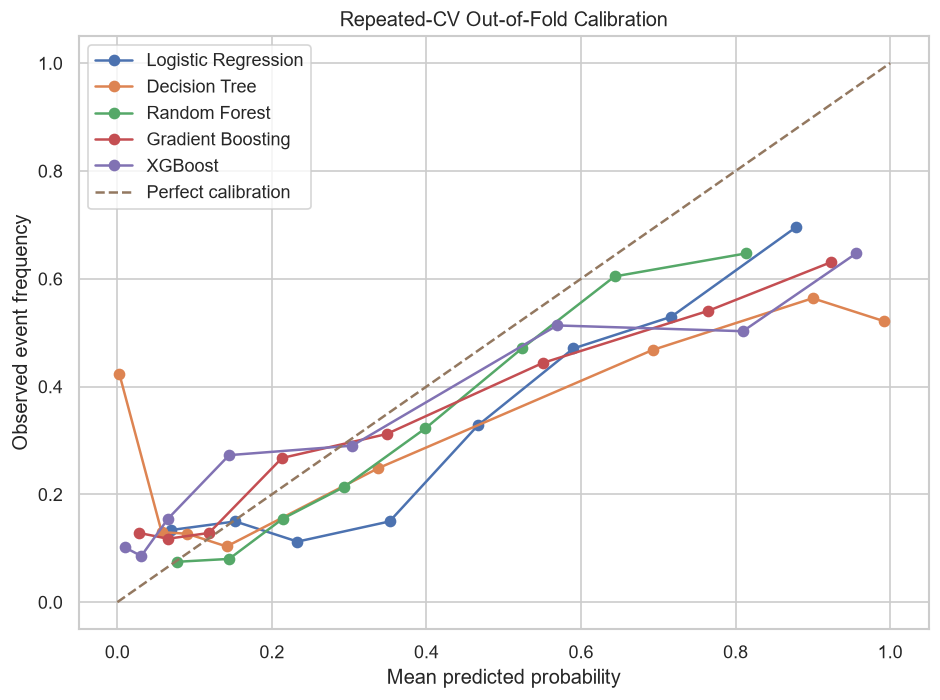

,threshold,sensitivity,specificity,PPV,accuracy
0,0.10,0.977,0.129,0.347,0.401
1,0.15,0.950,0.271,0.381,0.489
2,0.20,0.919,0.386,0.414,0.557
3,0.25,0.879,0.500,0.454,0.622
4,0.30,0.844,0.585,0.490,0.668
5,0.35,0.781,0.651,0.514,0.693
6,0.40,0.733,0.705,0.541,0.714
7,0.45,0.685,0.752,0.566,0.730
8,0.50,0.619,0.802,0.596,0.743
9,0.55,0.544,0.833,0.607,0.740


In [14]:

# =============================================================================
# 10. CALIBRATION
# =============================================================================
# Use out-of-fold predictions from the repeated CV store.
plot_models = list(corrected_models.keys())

plt.figure(figsize=(8, 6))
for name in plot_models:
    yt = oof_store[name]["y_true"]
    pr = oof_store[name]["prob"]
    frac_pos, mean_pred = calibration_curve(yt, pr, n_bins=8, strategy="quantile")
    plt.plot(mean_pred, frac_pos, marker="o", label=name)

plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed event frequency")
plt.title("Repeated-CV Out-of-Fold Calibration")
plt.legend()
plt.tight_layout()
plt.show()

# Threshold table for the best model by mean ROC-AUC.
best_cv_model = (
    cv_long[cv_long["Metric"] == "roc_auc"]
    .sort_values("Mean", ascending=False)
    .iloc[0]["Model"]
)

yt = oof_store[best_cv_model]["y_true"]
pr = oof_store[best_cv_model]["prob"]

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    pred = (pr >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred).ravel()

    sensitivity = tp / (tp + fn) if tp + fn else np.nan
    specificity = tn / (tn + fp) if tn + fp else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan

    threshold_rows.append({
        "threshold": threshold,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "PPV": ppv,
        "accuracy": accuracy_score(yt, pred)
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(3))



## 11. Held-out permutation importance

Tree impurity importance is not treated as a clinical "risk factor" score.

Instead, permutation importance is calculated on held-out data. A feature is important if permuting it degrades predictive performance.

Because the dataset is small, the result should be interpreted as **predictive association**, not causality.


,feature,mean_auc_decrease,sd
7,serum_creatinine,0.1249,0.0506
4,ejection_fraction,0.0849,0.0232
0,age,0.0568,0.0106
8,serum_sodium,0.0142,0.0177
2,creatinine_phosphokinase,0.0117,0.0104
5,high_blood_pressure,0.0082,0.0060
10,smoking,0.0045,0.0057
9,sex,0.0044,0.0033
1,anaemia,0.0034,0.0061
3,diabetes,-0.0007,0.0027


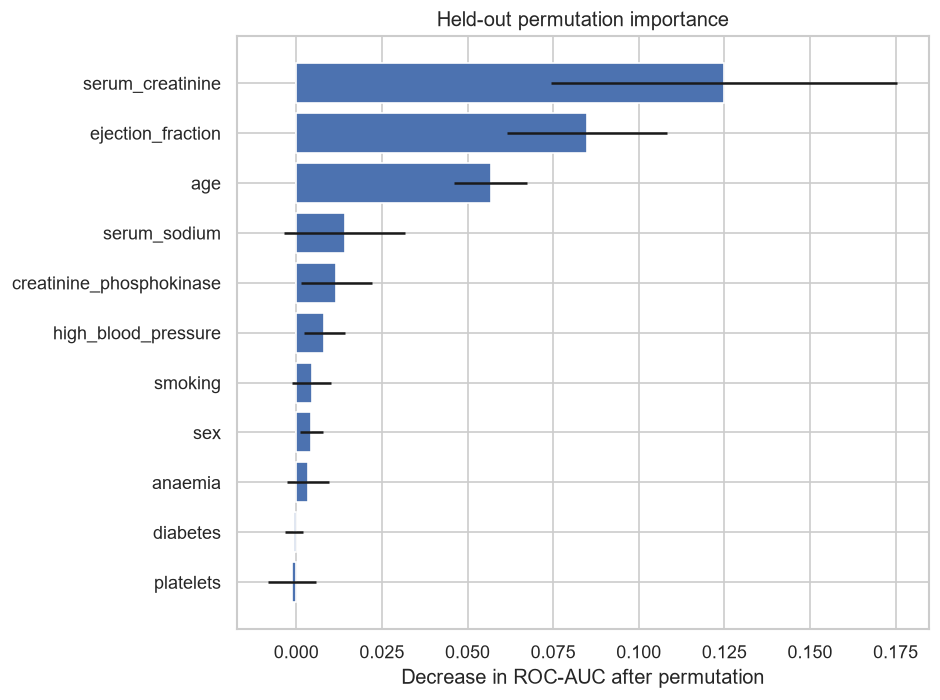

In [15]:

# =============================================================================
# 11. PERMUTATION IMPORTANCE
# =============================================================================
# Use one untouched holdout for a readable feature-importance plot.
importance_model = make_smotenc_pipeline(
    RandomForestClassifier(
        n_estimators=300, max_depth=6,
        random_state=RANDOM_STATE, n_jobs=-1
    )
)
importance_model.fit(X_train, y_train)

perm = permutation_importance(
    importance_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=50,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": clf_features,
    "mean_auc_decrease": perm.importances_mean,
    "sd": perm.importances_std
}).sort_values("mean_auc_decrease", ascending=False)

display(perm_df.round(4))

plt.figure(figsize=(8, 6))
plot_df = perm_df.sort_values("mean_auc_decrease")
plt.barh(plot_df["feature"], plot_df["mean_auc_decrease"], xerr=plot_df["sd"])
plt.xlabel("Decrease in ROC-AUC after permutation")
plt.title("Held-out permutation importance")
plt.tight_layout()
plt.show()



## 12. Optional SHAP analysis

SHAP can provide local and global explanations, but it is an explanatory tool rather than proof of causal risk.

This section is optional because SHAP versions differ across XGBoost/scikit-learn environments.


In [16]:

# =============================================================================
# 12. OPTIONAL SHAP
# =============================================================================
try:
    import shap

    xgb_model = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    shap_pipe = make_smotenc_pipeline(xgb_model)
    shap_pipe.fit(X_train, y_train)

    # Explain the final XGBoost estimator on the original holdout.
    fitted_xgb = shap_pipe.named_steps["model"]
    explainer = shap.TreeExplainer(fitted_xgb)

    # SMOTENC changes the training distribution but not the columns.
    shap_values = explainer.shap_values(X_test)

    shap.summary_plot(
        shap_values,
        X_test,
        feature_names=clf_features,
        show=False
    )
    plt.tight_layout()
    plt.show()

except Exception as exc:
    print("SHAP section skipped:", repr(exc))


SHAP section skipped: ModuleNotFoundError("No module named 'shap'")



# 13. Survival analysis — corrected protocol

`DEATH_EVENT = 0` does **not necessarily mean the patient will never die**. It means death was not observed during that patient's follow-up.

Therefore:

- classification of `DEATH_EVENT` is a fixed-horizon/event-observation task;
- survival analysis should model `time` and censoring jointly;
- **SMOTE must not be used on the survival dataset**;
- outlier filtering should not remove clinically extreme patients from the primary survival analysis.

The Cox model below uses the original 299 patients.


In [17]:

# =============================================================================
# 13. COX PROPORTIONAL HAZARDS
# =============================================================================
survival_continuous = [
    "age", "creatinine_phosphokinase", "ejection_fraction",
    "platelets", "serum_creatinine", "serum_sodium"
]
survival_binary = [
    "anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"
]

# Standardize continuous predictors so HRs are per one SD increase.
surv_model_df = df[["time", "DEATH_EVENT"] + survival_continuous + survival_binary].copy()

for col in survival_continuous:
    mean = surv_model_df[col].mean()
    sd = surv_model_df[col].std(ddof=0)
    surv_model_df[col + "_z"] = (surv_model_df[col] - mean) / sd

cox_features = [c + "_z" for c in survival_continuous] + survival_binary

cph = CoxPHFitter()
cph.fit(
    surv_model_df[["time", "DEATH_EVENT"] + cox_features],
    duration_col="time",
    event_col="DEATH_EVENT"
)

cox_summary = cph.summary[
    ["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%",
     "z", "p", "-log2(p)"]
].rename(columns={
    "coef": "log_HR",
    "exp(coef)": "HR",
    "exp(coef) lower 95%": "HR_lower_95",
    "exp(coef) upper 95%": "HR_upper_95",
    "z": "z",
    "p": "p_value",
})

display(cox_summary.sort_values("p_value").round(4))

print("Cox concordance index:", round(cph.concordance_index_, 4))


,log_HR,HR,HR_lower_95,HR_upper_95,z,p_value,-log2(p)
covariate,,,,,,,
age_z,0.5511,1.7351,1.3967,2.1557,4.9773,0.0000,20.5645
ejection_fraction_z,-0.5782,0.5609,0.4401,0.7149,-4.6719,0.0000,18.3540
serum_creatinine_z,0.3316,1.3931,1.2087,1.6058,4.5751,0.0000,17.6806
creatinine_phosphokinase_z,0.2138,1.2384,1.0258,1.4950,2.2255,0.0260,5.2627
high_blood_pressure,0.4757,1.6092,1.0534,2.4583,2.2005,0.0278,5.1704
anaemia,0.4601,1.5843,1.0358,2.4233,2.1220,0.0338,4.8854
serum_sodium_z,-0.1946,0.8231,0.6733,1.0062,-1.8993,0.0575,4.1195
sex,-0.2375,0.7886,0.4816,1.2913,-0.9440,0.3452,1.5346
diabetes,0.1399,1.1501,0.7427,1.7811,0.6269,0.5307,0.9139


Cox concordance index: 0.7408


In [18]:

# =============================================================================
# 13A. PROPORTIONAL HAZARDS CHECK
# =============================================================================
try:
    ph_test = cph.check_assumptions(
        surv_model_df[["time", "DEATH_EVENT"] + cox_features],
        p_value_threshold=0.05,
        show_plots=False
    )
except Exception as exc:
    print("PH check completed with diagnostic output / warning:", exc)


The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'ejection_fraction_z' failed the non-proportional test: p-value is 0.0127.

   Advice 1: the functional form of the variable 'ejection_fraction_z' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'ejection_fraction_z' using pd.cut, and then specify it in
`strata=['ejection_fraction_z', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebo


### Interpretation rule for standardized hazard ratios

For a continuous feature, `HR` now represents the relative hazard for a **one-standard-deviation increase**, rather than a one-unit increase.

This makes effect sizes more comparable across:

- age;
- serum creatinine;
- CPK;
- ejection fraction;
- platelets;
- serum sodium.

It does not make the model causal.


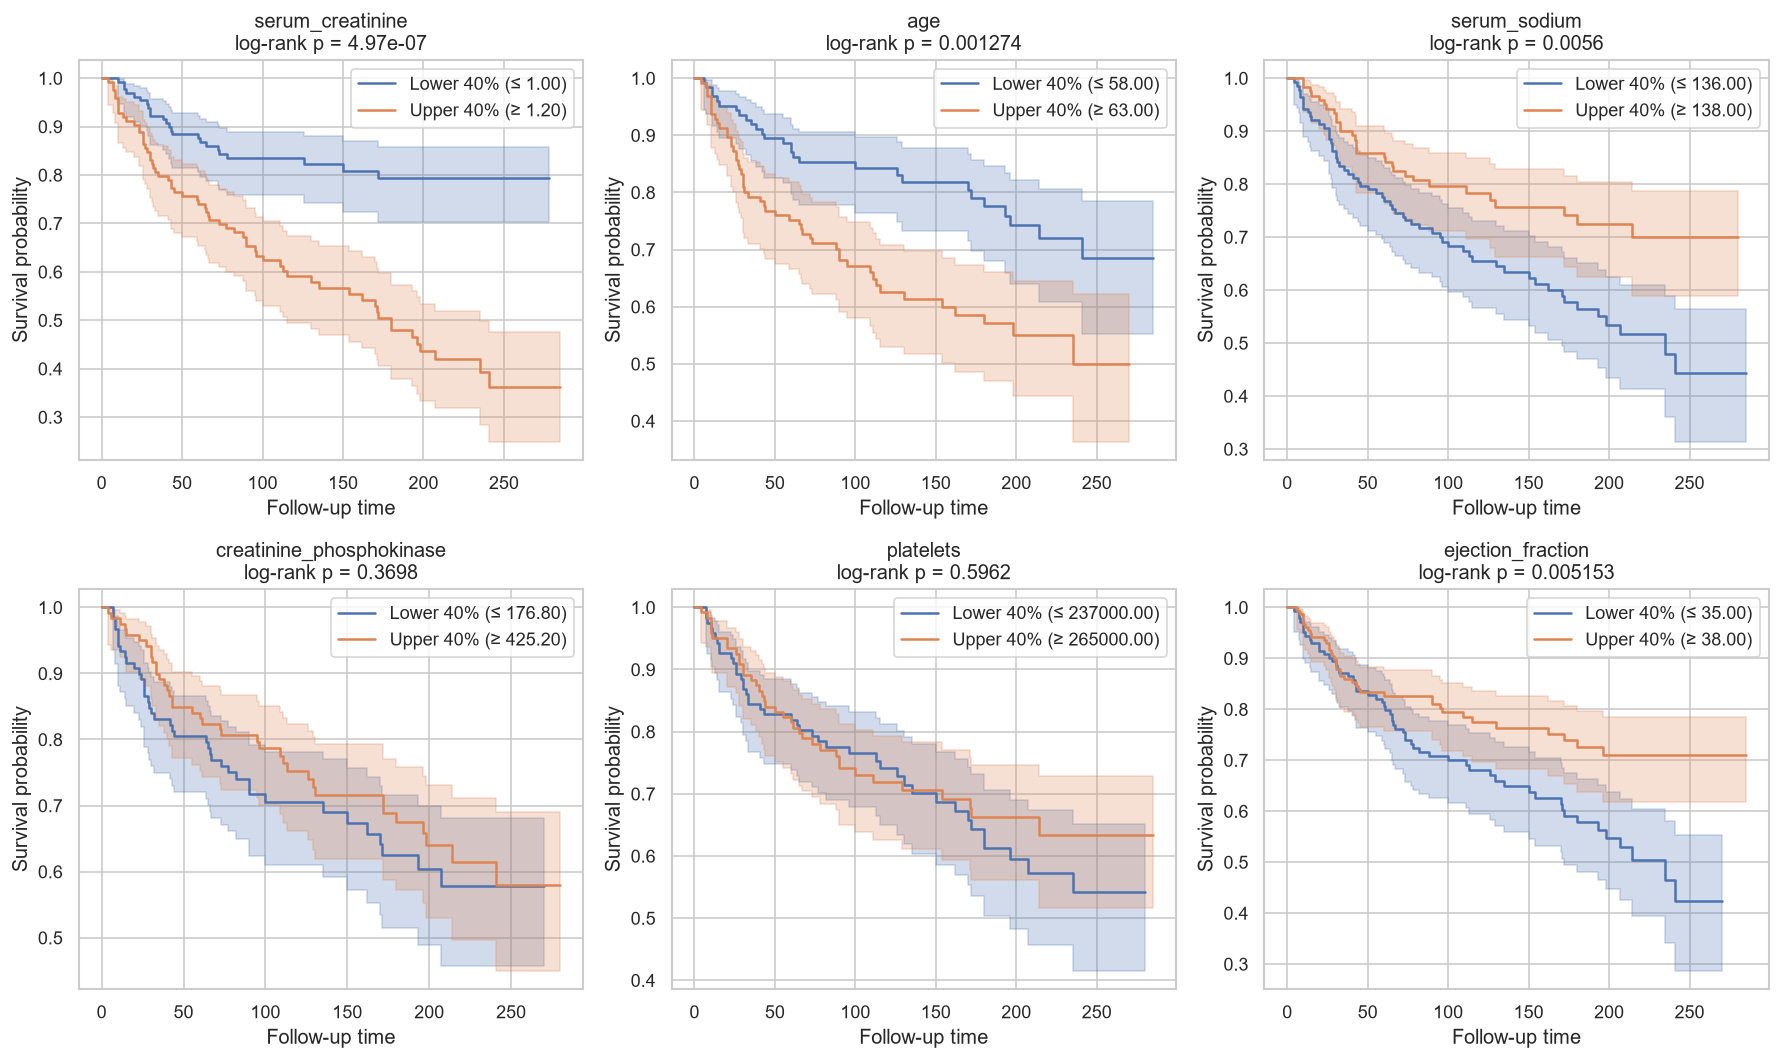

,feature,lower_cut,upper_cut,logrank_p,bonferroni_p
0,serum_creatinine,1.0,1.2,0.00000,0.00000
1,age,58.0,63.0,0.00127,0.00764
5,ejection_fraction,35.0,38.0,0.00515,0.03092
2,serum_sodium,136.0,138.0,0.00560,0.03360
3,creatinine_phosphokinase,176.8,425.2,0.36976,1.00000
4,platelets,237000.0,265000.0,0.59623,1.00000


In [19]:

# =============================================================================
# 14. KAPLAN-MEIER SENSITIVITY ANALYSIS
# =============================================================================
# This reproduces the paper's lower-40% vs upper-40% idea,
# but adds log-rank tests and explicitly calls it a sensitivity analysis.

km_results = []

def km_two_group(df_in, feature, q_low=0.40, q_high=0.60):
    lo = df_in[feature].quantile(q_low)
    hi = df_in[feature].quantile(q_high)

    low = df_in[feature] <= lo
    high = df_in[feature] >= hi

    result = logrank_test(
        df_in.loc[low, "time"],
        df_in.loc[high, "time"],
        event_observed_A=df_in.loc[low, "DEATH_EVENT"],
        event_observed_B=df_in.loc[high, "DEATH_EVENT"]
    )

    return lo, hi, low, high, result.p_value

km_features = [
    "serum_creatinine", "age", "serum_sodium",
    "creatinine_phosphokinase", "platelets", "ejection_fraction"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.ravel(), km_features):
    lo, hi, low, high, p = km_two_group(df, feature)

    kmf_low = KaplanMeierFitter()
    kmf_high = KaplanMeierFitter()

    kmf_low.fit(
        df.loc[low, "time"],
        event_observed=df.loc[low, "DEATH_EVENT"],
        label=f"Lower 40% (≤ {lo:.2f})"
    )
    kmf_high.fit(
        df.loc[high, "time"],
        event_observed=df.loc[high, "DEATH_EVENT"],
        label=f"Upper 40% (≥ {hi:.2f})"
    )

    kmf_low.plot_survival_function(ax=ax, ci_show=True)
    kmf_high.plot_survival_function(ax=ax, ci_show=True)

    ax.set_title(f"{feature}\nlog-rank p = {p:.4g}")
    ax.set_xlabel("Follow-up time")
    ax.set_ylabel("Survival probability")

    km_results.append({
        "feature": feature,
        "lower_cut": lo,
        "upper_cut": hi,
        "logrank_p": p
    })

plt.tight_layout()
plt.show()

km_results_df = pd.DataFrame(km_results)
km_results_df["bonferroni_p"] = np.minimum(
    km_results_df["logrank_p"] * len(km_results_df), 1.0
)
display(km_results_df.sort_values("logrank_p").round(5))



## 15. Optional Random Survival Forest

This section is optional. It uses `scikit-survival`, which may require a compatible compiled installation.

If available, the model is evaluated with cross-validated concordance index. It is not fitted to SMOTE data.


In [20]:

# =============================================================================
# 15. OPTIONAL RANDOM SURVIVAL FOREST
# =============================================================================
try:
    from sksurv.ensemble import RandomSurvivalForest
    from sksurv.util import Surv
    from sklearn.model_selection import KFold

    X_surv = df[survival_continuous + survival_binary].copy()
    y_surv = Surv.from_arrays(
        event=df["DEATH_EVENT"].astype(bool),
        time=df["time"].astype(float)
    )

    rsf = RandomSurvivalForest(
        n_estimators=300,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rsf_scores = []

    for tr, va in kf.split(X_surv):
        rsf.fit(X_surv.iloc[tr], y_surv[tr])
        score = rsf.score(X_surv.iloc[va], y_surv[va])
        rsf_scores.append(score)

    print(
        f"Random Survival Forest C-index: "
        f"{np.mean(rsf_scores):.3f} ± {np.std(rsf_scores, ddof=1):.3f}"
    )

except Exception as exc:
    print("Random Survival Forest skipped:", repr(exc))
    print("Install a compatible scikit-survival version if this analysis is required.")


Random Survival Forest skipped: ModuleNotFoundError("No module named 'sksurv'")
Install a compatible scikit-survival version if this analysis is required.



# 16. Direct audit of the paper's internal contradictions

The following checks are deliberately separated into:

- **Verified from the paper text/tables/figures**
- **Dataset-dependent checks performed by this notebook**
- **Inference that requires access to the authors' exact code**

The notebook does not silently turn an inference into a proven error.


In [21]:

# =============================================================================
# 16. AUDIT CHECKLIST
# =============================================================================
audit = [
    {
        "Issue": "Table 5 vs Table 6/Fig. 6 feature rankings",
        "Status": "Paper-level inconsistency to verify manually",
        "Reason": "The reported numeric coefficients and displayed rankings should agree; this notebook does not alter the paper tables."
    },
    {
        "Issue": "Fig. 5 PR-AUC text",
        "Status": "Verified from paper",
        "Reason": "The prose reports 90.6% for RF, while the figure legend assigns 0.906 to DTR and 0.978 to RF."
    },
    {
        "Issue": "Fig. 7(A) SS significance",
        "Status": "Verified from supplied paper figure/text",
        "Reason": "The displayed p-value and prose statement should be reconciled."
    },
    {
        "Issue": "Top-factor lists",
        "Status": "Verified",
        "Reason": "The abstract, conclusion, Table 6 and Section 3.4 do not use one consistent list."
    },
    {
        "Issue": "Table 8 vs significance claims",
        "Status": "Verified",
        "Reason": "The paper's Table 8 reports SS p=0.11 and platelets p=0.46, despite stronger wording elsewhere."
    },
    {
        "Issue": "Fig. 8(H) vs Table 8 scale",
        "Status": "Visual/manual verification required",
        "Reason": "A visual plot reading is approximate; compare the plotted coefficient with the numerical table."
    },
    {
        "Issue": "Fig. 4 vs Fig. 3 cleaning",
        "Status": "Paper-level inconsistency to investigate",
        "Reason": "The displayed KDE ranges appear broader than the cleaned boxplots; exact plotting dataframe is not provided."
    },
    {
        "Issue": "Table 2 counts/p-values",
        "Status": "Dataset-dependent and checkable below",
        "Reason": "The loaded CSV is compared directly against the paper's reported counts and p-values."
    },
    {
        "Issue": "Tiny single test split",
        "Status": "Verified methodological limitation",
        "Reason": "A 70/30 split of 299 observations gives only about 90 test observations."
    },
    {
        "Issue": "No repeated CV/external validation",
        "Status": "Verified from methods/results",
        "Reason": "The paper reports a single train/test split rather than repeated or external validation."
    },
    {
        "Issue": "SMOTE ordering",
        "Status": "Ambiguous but high-risk",
        "Reason": "The prose describes preprocessing before the train/test split; the exact implementation and whether synthetic observations entered the test set cannot be reconstructed from the paper alone."
    },
    {
        "Issue": "SMOTE for binary variables",
        "Status": "Methodological concern",
        "Reason": "Ordinary SMOTE can interpolate binary indicators; SMOTENC is preferable for mixed feature types."
    },
    {
        "Issue": "Log loss",
        "Status": "Strongly suspicious",
        "Reason": "Proper log loss requires predicted probabilities. The reported values match the scale expected from hard-label predictions with clipping."
    },
    {
        "Issue": "DTR labelled as classification accuracy",
        "Status": "Methodological inconsistency",
        "Reason": "A DecisionTreeRegressor is a regression estimator; its score is R², not classification accuracy."
    },
    {
        "Issue": "Censoring",
        "Status": "Verified conceptual concern",
        "Reason": "DEATH_EVENT=0 means death was not observed during follow-up; it is not equivalent to guaranteed long-term survival."
    },
    {
        "Issue": "Impurity feature importance",
        "Status": "Methodological concern",
        "Reason": "Impurity importance is a predictive split criterion, not a causal risk-factor measure."
    },
    {
        "Issue": "Cox on SMOTE data",
        "Status": "Must not be done in corrected analysis",
        "Reason": "SMOTE is not a valid way to synthesize right-censored survival observations."
    },
    {
        "Issue": "Kaplan-Meier 40/40 split",
        "Status": "Sensitivity analysis only",
        "Reason": "Cut-points are arbitrary; log-rank tests and multiplicity correction are added here."
    },
    {
        "Issue": "Unsupervised validation circularity",
        "Status": "Methodological concern",
        "Reason": "Selecting features using labels and then assessing label separation in clusters does not constitute independent validation."
    },
]

audit_df = pd.DataFrame(audit)
display(audit_df)


,Issue,Status,Reason
0,Table 5 vs Table 6/Fig. 6 feature rankings,Paper-level inconsistency to verify manually,The reported numeric coefficients and displaye...
1,Fig. 5 PR-AUC text,Verified from paper,"The prose reports 90.6% for RF, while the figu..."
2,Fig. 7(A) SS significance,Verified from supplied paper figure/text,The displayed p-value and prose statement shou...
3,Top-factor lists,Verified,"The abstract, conclusion, Table 6 and Section ..."
4,Table 8 vs significance claims,Verified,The paper's Table 8 reports SS p=0.11 and plat...
5,Fig. 8(H) vs Table 8 scale,Visual/manual verification required,A visual plot reading is approximate; compare ...
6,Fig. 4 vs Fig. 3 cleaning,Paper-level inconsistency to investigate,The displayed KDE ranges appear broader than t...
7,Table 2 counts/p-values,Dataset-dependent and checkable below,The loaded CSV is compared directly against th...
8,Tiny single test split,Verified methodological limitation,A 70/30 split of 299 observations gives only a...
9,No repeated CV/external validation,Verified from methods/results,The paper reports a single train/test split ra...



# 17. Special check: reported accuracy arithmetic

A 70/30 split of 299 observations gives approximately 90 test observations.

The reported values:

- 97.78%
- 96.67%
- 94.44%

are numerically compatible with:

- 88/90;
- 87/90;
- 85/90.

That arithmetic alone does **not** prove that the paper used exactly those predictions. It only establishes that the reported percentages are compatible with a 90-case test set.


In [22]:

# =============================================================================
# 17. ACCURACY ARITHMETIC
# =============================================================================
for n_test in [89, 90, 91, 92]:
    for pct in [97.78, 96.67, 94.44]:
        correct = pct / 100 * n_test
        if abs(correct - round(correct)) < 0.02:
            print(
                f"{pct:.2f}% is compatible with {round(correct)}/{n_test}"
            )


97.78% is compatible with 88/90
96.67% is compatible with 87/90
94.44% is compatible with 85/90



# 18. Time sensitivity analysis

The paper's classification table appears to exclude `time` from the feature-importance table, but the methods do not clearly describe the exact classifier feature set.

We therefore compare:

- **Primary:** baseline variables only, excluding `time`;
- **Sensitivity:** baseline variables + `time`.

If adding `time` substantially increases performance, that is evidence that follow-up information is driving the classifier and that the prediction question has changed.


In [23]:

# =============================================================================
# 18. TIME-INCLUSION SENSITIVITY
# =============================================================================
X_with_time = df[[c for c in df.columns if c != "DEATH_EVENT"]].copy()

binary_with_time = [
    c for c in X_with_time.columns
    if set(df[c].dropna().unique()).issubset({0, 1})
]
cat_idx_time = [X_with_time.columns.tolist().index(c) for c in binary_with_time]

def make_time_pipe(model):
    return ImbPipeline([
        ("smotenc", SMOTENC(
            categorical_features=cat_idx_time,
            random_state=RANDOM_STATE
        )),
        ("model", model)
    ])

time_rows = []
for include_time, X_use, maker in [
    ("Excluded", X, make_smotenc_pipeline),
    ("Included", X_with_time, make_time_pipe),
]:
    vals = []
    for tr_idx, va_idx in skf.split(X_use, y):
        pipe = maker(RandomForestClassifier(
            n_estimators=200, max_depth=6,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
        pipe.fit(X_use.iloc[tr_idx], y.iloc[tr_idx])
        prob = pipe.predict_proba(X_use.iloc[va_idx])[:, 1]
        pred = (prob >= 0.5).astype(int)
        vals.append([
            accuracy_score(y.iloc[va_idx], pred),
            balanced_accuracy_score(y.iloc[va_idx], pred),
            roc_auc_score(y.iloc[va_idx], prob)
        ])

    vals = np.array(vals)
    time_rows.append({
        "Time": include_time,
        "Accuracy": f"{vals[:,0].mean():.3f} ± {vals[:,0].std(ddof=1):.3f}",
        "Balanced Accuracy": f"{vals[:,1].mean():.3f} ± {vals[:,1].std(ddof=1):.3f}",
        "ROC-AUC": f"{vals[:,2].mean():.3f} ± {vals[:,2].std(ddof=1):.3f}",
    })

display(pd.DataFrame(time_rows))


,Time,Accuracy,Balanced Accuracy,ROC-AUC
0,Excluded,0.759 ± 0.079,0.739 ± 0.093,0.795 ± 0.100
1,Included,0.853 ± 0.069,0.830 ± 0.088,0.919 ± 0.046



# 19. Final reproducibility table

The final table distinguishes:

- the paper's reported result;
- the paper-style diagnostic reproduction;
- the leakage-free holdout;
- repeated leakage-free cross-validation.

The exact numbers in the last three rows are generated from **your loaded CSV**, so they should be reported with the dataset version and random seed.


In [24]:

# =============================================================================
# 19. FINAL SUMMARY
# =============================================================================
rf_cv = cv_long[
    (cv_long["Model"] == "Random Forest") &
    (cv_long["Metric"].isin(["accuracy", "balanced_accuracy", "f1", "roc_auc", "pr_auc", "log_loss"]))
].copy()

summary_rows = [
    {
        "Protocol": "Paper reported RF",
        "Accuracy": 0.9778,
        "ROC-AUC": 0.990,
        "Notes": "Reported in paper; single 70/30 evaluation."
    },
    {
        "Protocol": "Paper-style diagnostic",
        "Accuracy": paper_style_results.loc[
            paper_style_results["Model"] == "RF", "Accuracy"
        ].iloc[0],
        "ROC-AUC": paper_style_results.loc[
            paper_style_results["Model"] == "RF", "ROC-AUC"
        ].iloc[0],
        "Notes": "Global IQR filtering + global ordinary SMOTE + split; leakage-prone."
    },
    {
        "Protocol": "Leakage-free 70/30",
        "Accuracy": holdout_results.loc[
            holdout_results["Model"] == "Random Forest", "Accuracy"
        ].iloc[0],
        "ROC-AUC": holdout_results.loc[
            holdout_results["Model"] == "Random Forest", "ROC-AUC"
        ].iloc[0],
        "Notes": "SMOTENC fitted on training data only."
    },
    {
        "Protocol": "Repeated 10x5-fold CV",
        "Accuracy": rf_cv.loc[rf_cv["Metric"] == "accuracy", "Mean"].iloc[0],
        "ROC-AUC": rf_cv.loc[rf_cv["Metric"] == "roc_auc", "Mean"].iloc[0],
        "Notes": "Primary generalization estimate."
    }
]

final_summary = pd.DataFrame(summary_rows)
display(final_summary.round(4))


,Protocol,Accuracy,ROC-AUC,Notes
0,Paper reported RF,0.9778,0.9900,Reported in paper; single 70/30 evaluation.
1,Paper-style diagnostic,0.8571,0.9288,Global IQR filtering + global ordinary SMOTE +...
2,Leakage-free 70/30,0.7444,0.7846,SMOTENC fitted on training data only.
3,Repeated 10x5-fold CV,0.7434,0.7834,Primary generalization estimate.



# 20. Conclusions to use in a paper/report

### What can be claimed safely

1. The published study reports 97.78% Random Forest accuracy, but a single 70/30 split on only 299 observations provides little uncertainty information.
2. The paper's preprocessing description is not detailed enough to reconstruct every implementation choice.
3. Applying SMOTE before a train/test split is a leakage risk because synthetic observations are generated using the full dataset. The paper's exact code is required to establish whether this actually happened.
4. Ordinary SMOTE is not ideal for mixed binary/continuous clinical variables; SMOTENC or class weighting is preferable.
5. `DEATH_EVENT=0` is not equivalent to guaranteed survival, because follow-up is finite and censoring exists.
6. A DecisionTreeRegressor should not be compared with classifiers using ordinary classification accuracy unless a separate, explicitly defined thresholding procedure is used.
7. Log loss must be calculated from predicted probabilities.
8. Tree impurity importance should not be described as causal risk-factor importance.
9. Cox survival analysis should use the original censored cohort, not SMOTE-generated survival records.
10. The most defensible predictive performance estimate is the leakage-free repeated cross-validation result, not the single paper-reported accuracy.

### What should NOT be claimed without further evidence

- "The paper's 97.78% accuracy is definitely caused by SMOTE leakage."
- "The authors definitely used the test set during tuning."
- "The paper definitely used SMOTE before splitting."
- "A feature is a causal risk factor merely because it has high tree importance."
- "A KDE range is a clinically safe range."

Use wording such as **"we could not reproduce"**, **"the methods are insufficiently specified"**, or **"this creates a potential source of leakage"** unless the authors' original code proves the stronger statement.



# 21. Export results

The next cell writes the main audit and performance tables to an Excel workbook.

This makes the analysis easier to inspect and include in a reproducibility report.


In [25]:

# =============================================================================
# 21. EXPORT
# =============================================================================
output_file = "heart_failure_rigorous_reanalysis_results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    paper_claims.to_excel(writer, sheet_name="cohort_audit", index=False)
    cat_audit.to_excel(writer, sheet_name="categorical_audit", index=False)
    num_audit.to_excel(writer, sheet_name="numeric_audit", index=False)
    removal_log.to_excel(writer, sheet_name="outlier_audit", index=False)
    paper_style_results.to_excel(writer, sheet_name="paper_style", index=False)
    holdout_results.to_excel(writer, sheet_name="holdout", index=False)
    cv_long.to_excel(writer, sheet_name="repeated_cv", index=False)
    balance_rows_df = pd.DataFrame(balance_rows)
    balance_rows_df.to_excel(writer, sheet_name="balancing", index=False)
    perm_df.to_excel(writer, sheet_name="permutation_importance", index=False)
    cox_summary.to_excel(writer, sheet_name="cox", index=True)
    km_results_df.to_excel(writer, sheet_name="km_logrank", index=False)
    audit_df.to_excel(writer, sheet_name="paper_audit", index=False)
    final_summary.to_excel(writer, sheet_name="final_summary", index=False)

print("Saved:", output_file)


Saved: heart_failure_rigorous_reanalysis_results.xlsx
